# Install & import libraries

In [1]:
!pip install pandas numpy scikit-learn gensim matplotlib seaborn

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import gensim.downloader as api

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load training set

In [3]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

train_df = train_df[['label', 'text']].dropna()

X_train = train_df['text'].astype(str)
y_train = train_df['label']

X_test = test_df['text'].astype(str)
y_test = test_df['label']


print(train_df.head())
print(train_df['label'].value_counts())

   label                                               text
0      0                         Going on nothing great.bye
1      0                      I wont. So wat's wit the guys
2      0            Ok k..sry i knw 2 siva..tats y i askd..
3      0  Where are you ? What do you do ? How can you s...
4      0       Have you not finished work yet or something?
label
0    3859
1     598
Name: count, dtype: int64


# Pretrained Word2Vec and GloVe vectors

Using pretrained embeddings for simplicity

In [4]:
word2vec_model = api.load("word2vec-google-news-300")
glove_model = api.load("glove-wiki-gigaword-100")

[==================================================] 100.0% 1662.8/1662.8MB downloaded
[==================================================] 100.0% 128.1/128.1MB downloaded


In [5]:
def average_word_vectors(text, model):
    words = text.split()

    vectors = [ model[word] for word in words if word in model ]

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)

## Word2Vec into vectors

In [6]:
X_train_w2v = np.array([ average_word_vectors(text, word2vec_model) for text in X_train ])

X_test_w2v = np.array([ average_word_vectors(text, word2vec_model) for text in X_test ])

## GloVe into vectors

In [7]:
X_train_glove = np.array([ average_word_vectors(text, glove_model) for text in X_train ])

X_test_glove = np.array([ average_word_vectors(text, glove_model) for text in X_test ])

# KNN with Word2Vec

## Training

In [8]:
knn = KNeighborsClassifier()

param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 15],
    'weights': ['uniform', 'distance'],
    'metric': ['cosine', 'euclidean']
}

grid_w2v = GridSearchCV(
    knn,
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

start_time = time.perf_counter()

grid_w2v.fit(X_train_w2v, y_train)
y_pred_w2v = grid_w2v.predict(X_test_w2v) # evaluation

w2v_runtime = time.perf_counter() - start_time

print("Best Word2Vec parameters:")
print(grid_w2v.best_params_)

print("Word2Vec + KNN Results")
print(classification_report(y_test, y_pred_w2v))

Best Word2Vec parameters:
{'metric': 'cosine', 'n_neighbors': 3, 'weights': 'distance'}
Word2Vec + KNN Results
              precision    recall  f1-score   support

           0       0.98      0.97      0.97       966
           1       0.83      0.85      0.84       149

    accuracy                           0.96      1115
   macro avg       0.90      0.91      0.91      1115
weighted avg       0.96      0.96      0.96      1115



# KNN with GloVe

## Training

In [9]:
grid_glove = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

start_time = time.perf_counter()

grid_glove.fit(X_train_glove, y_train)
y_pred_glove = grid_glove.predict(X_test_glove)

glove_runtime = time.perf_counter() - start_time

print("Best GloVe parameters:")
print(grid_glove.best_params_)

print("GloVe + KNN Results")
print(classification_report(y_test, y_pred_glove))

Best GloVe parameters:
{'metric': 'cosine', 'n_neighbors': 11, 'weights': 'distance'}
GloVe + KNN Results
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       966
           1       0.80      0.81      0.80       149

    accuracy                           0.95      1115
   macro avg       0.88      0.89      0.89      1115
weighted avg       0.95      0.95      0.95      1115



# TF-IDF + KNN baseline

## Training

In [10]:
tfidf_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer( max_features=10000, ngram_range=(1, 2) )),
    ('knn', KNeighborsClassifier())
])

tfidf_params = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 15],
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['cosine', 'euclidean']
}

grid_tfidf = GridSearchCV(
    tfidf_pipeline,
    tfidf_params,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

start_time = time.perf_counter()

grid_tfidf.fit(X_train, y_train)
y_pred_tfidf = grid_tfidf.predict(X_test)

tfidf_runtime = time.perf_counter() - start_time

print("Best TF-IDF parameters:")
print(grid_tfidf.best_params_)

print("TF-IDF + KNN Results")
print(classification_report(y_test, y_pred_tfidf))

Best TF-IDF parameters:
{'knn__metric': 'cosine', 'knn__n_neighbors': 5, 'knn__weights': 'distance'}
TF-IDF + KNN Results
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       966
           1       0.98      0.85      0.91       149

    accuracy                           0.98      1115
   macro avg       0.98      0.92      0.95      1115
weighted avg       0.98      0.98      0.98      1115



# Comparison between the three

In [19]:
# Identify the spam class
spam_label = next(label for label in y_test.unique() if label == 1)

# Calculate spam-class F1 scores
spam_f1_w2v = f1_score(
    y_test, y_pred_w2v, labels=[spam_label],
    average=None, zero_division=0
)[0]

spam_f1_glove = f1_score(
    y_test, y_pred_glove, labels=[spam_label],
    average=None, zero_division=0
)[0]

spam_f1_tfidf = f1_score(
    y_test, y_pred_tfidf, labels=[spam_label],
    average=None, zero_division=0
)[0]


# Get dimensionality
w2v_dimensions = X_train_w2v.shape[1]
glove_dimensions = X_train_glove.shape[1]
tfidf_dimensions = len(grid_tfidf.best_estimator_['tfidf'].vocabulary_)


# Get best K values
w2v_best_k = grid_w2v.best_params_['n_neighbors']
glove_best_k = grid_glove.best_params_['n_neighbors']
tfidf_best_k = grid_tfidf.best_params_['knn__n_neighbors']

predictions = [y_pred_w2v, y_pred_glove, y_pred_tfidf]


# Create comparison table
comparison = pd.DataFrame({
    'Representation': [ 'Word2Vec Average', 'GloVe Average', 'TF-IDF' ],
    'Dimensionality': [ w2v_dimensions, glove_dimensions, tfidf_dimensions ],
    'Best K': [ w2v_best_k, glove_best_k, tfidf_best_k ],
    'Spam-class F1 Score': [ spam_f1_w2v, spam_f1_glove, spam_f1_tfidf ],
    'Runtime (seconds)': [ w2v_runtime, glove_runtime, tfidf_runtime ],
    'Accuracy': [ accuracy_score(y_test, pred) for pred in predictions ],
    'Precision': [ precision_score(y_test, pred, average='macro', zero_division=0) for pred in predictions ],
    'Recall': [ recall_score(y_test, pred, average='macro', zero_division=0) for pred in predictions ],
    'Macro F1 Score': [ f1_score(y_test, pred, average='macro', zero_division=0) for pred in predictions ],
})


# Display comparison table
pd.set_option('display.max_colwidth', None)

print("\n========== MODEL COMPARISON ==========\n")
print(comparison.to_string(index=False))


# Save comparison table
comparison.to_csv('model_comparison.csv', index=False )


========== MODEL COMPARISON ==========

  Representation  Dimensionality  Best K  Spam-class F1 Score  Runtime (seconds)  Accuracy  Precision   Recall  Macro F1 Score
Word2Vec Average             300       3             0.837209          17.809340  0.956054   0.902532 0.909361        0.905904
   GloVe Average             100      11             0.802676           6.841342  0.947085   0.884974 0.887157        0.886061
          TF-IDF           10000       5             0.906475          37.950346  0.976682   0.976709 0.921266        0.946578


# Visualization

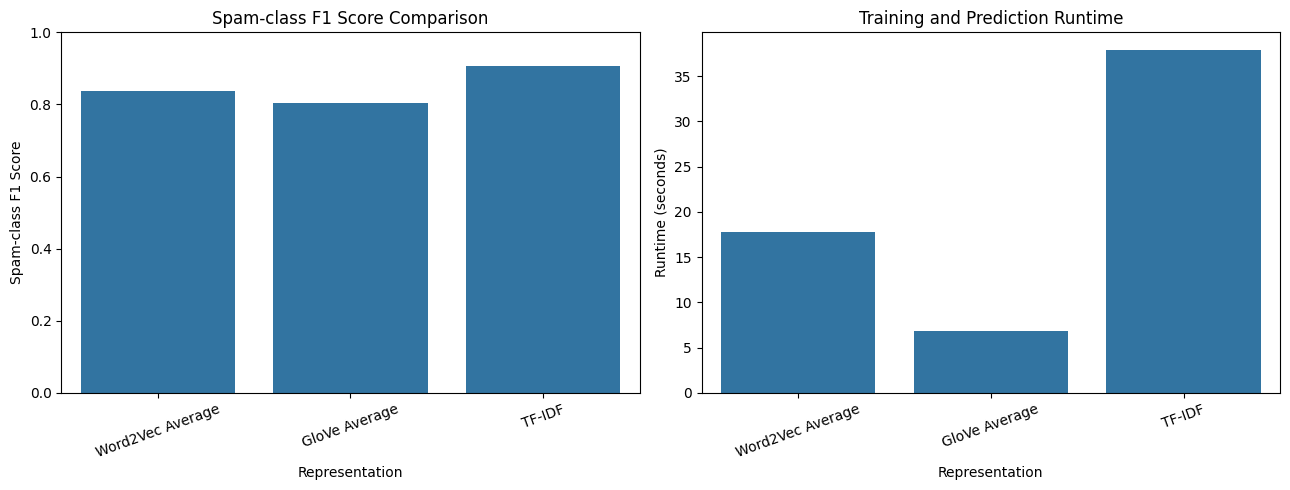

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Spam-class F1 comparison
sns.barplot(
    data=comparison, x='Representation',
    y='Spam-class F1 Score', ax=axes[0]
)

axes[0].set_title('Spam-class F1 Score Comparison')
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis='x', rotation=20)


# Runtime comparison
sns.barplot(
    data=comparison, x='Representation',
    y='Runtime (seconds)', ax=axes[1]
)

axes[1].set_title('Training and Prediction Runtime')
axes[1].set_ylabel('Runtime (seconds)')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

# Confusion matrices

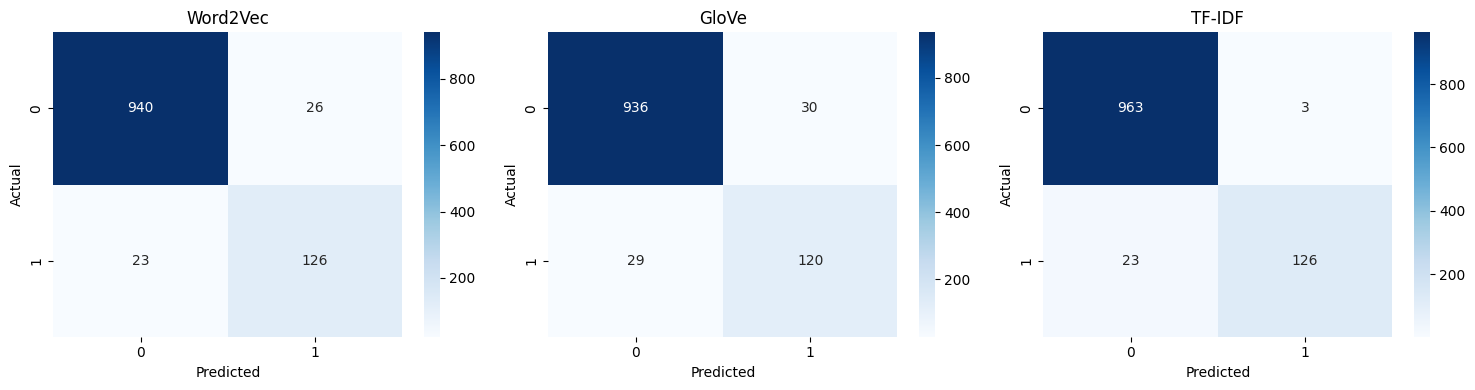

In [21]:
predictions = {
    'Word2Vec': y_pred_w2v,
    'GloVe': y_pred_glove,
    'TF-IDF': y_pred_tfidf
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, predictions_model) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, predictions_model)
    sns.heatmap(cm, annot=True,fmt='d', cmap='Blues', ax=ax)

    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

# Comparative Analysis and Conclusion

The experimental results demonstrate that TF-IDF combined with KNN achieves the best overall performance among the three approaches, with an accuracy of 97.67%, a macro F1-score of 0.9466, and a Spam-class F1-score of 0.9867. Word2Vec with KNN achieves an accuracy of 95.61% and a macro F1-score of 0.9059, while GloVe with KNN achieves an accuracy of 94.71% and a macro F1-score of 0.8861.

TF-IDF performs better because it considers the importance of individual words and phrases in the dataset. By using unigram and bigram features, it can capture useful local word relationships and expressions, including some negation patterns. Its main strength is its ability to identify discriminative words and phrases that are particularly useful for distinguishing spam from legitimate messages. However, its main weakness is its high-dimensional and sparse feature representation, which increases computational requirements. This is also reflected in the experimental runtime, where TF-IDF requires approximately 37.95 seconds, the highest among the three approaches.

Word2Vec provides dense 300-dimensional word embeddings that capture semantic relationships and similarities between words. Its main strength is its ability to represent words with similar meanings using similar numerical vectors. However, averaging word embeddings removes word order and contextual information, which can limit its effectiveness when classifying short SMS messages containing informal language, negation, or context-dependent expressions. Its measured runtime is approximately 17.81 seconds.

Similarly, GloVe provides a more compact 100-dimensional representation, reducing the feature dimensionality compared with Word2Vec. Its main strength is its ability to capture semantic relationships while using fewer dimensions and achieving the lowest measured runtime of approximately 6.84 seconds. Nevertheless, averaging GloVe embeddings also removes word order and contextual information, and its lower-dimensional representation does not necessarily guarantee better classification performance. In this experiment, GloVe achieves the lowest accuracy and macro F1-score among the three approaches.

An important observation is the difference between Spam-class F1 and macro F1. TF-IDF achieves a Spam-class F1-score of 0.906475 and a macro F1-score of 0.9466, indicating excellent performance in identifying spam messages and a balanced evaluation across both classes. The same pattern is observed with Word2Vec and GloVe, suggesting that evaluating both classes is important rather than relying exclusively on spam detection performance.

Therefore, based on the observed experimental results, TF-IDF combined with KNN is the best-performing approach for this dataset. Although it requires more computational time and has higher dimensionality, it provides the strongest classification performance. Word2Vec offers a useful semantic representation, while GloVe provides a more computationally efficient and compact alternative. Further evaluation using cross-validation, class-wise precision and recall, and an independent test set is recommended to confirm the reliability and generalizability of these results.